# Assignment 9: Multi-Output Linear Regression with the Linnerud Dataset

In this assignment, I will build a linear regression model that predicts three target variables at the same time (multi-output regression), using the Linnerud dataset from scikit-learn. The dataset contains body measurements and exercise results for 20 middle-aged men.

The assignment describes the inputs as age, weight, and height, and the targets as chin-ups, sit-ups, and jumps. In scikit-learn, the dataset actually stores the exercise results as "data" and the body measurements (weight, waist, and pulse) as "target", and it does not include age or height. To match the goal of the assignment, I used the body measurements (Weight, Waist, Pulse) as the features and the exercises (Chins, Situps, Jumps) as the three targets.

My steps:
- Load the data and split it into 80% training and 20% testing
- Explore the training data
- Train a Linear Regression model and evaluate it with R² and RMSE (Root Mean Squared Error) for each target
- Visualize the predictions and predict for one data point
- Try to improve the model and compare it with Lasso Regression

## Step 1: Import Libraries and Load the Dataset

In [7]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_linnerud
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [8]:
pd.set_option("display.max_columns", None)

In [3]:
linnerud = load_linnerud(as_frame=True)

In [9]:
# Check how scikit-learn stores the dataset
print("scikit-learn 'data' columns:  ", list(linnerud.data.columns))
print("scikit-learn 'target' columns:", list(linnerud.target.columns))

scikit-learn 'data' columns:   ['Chins', 'Situps', 'Jumps']
scikit-learn 'target' columns: ['Weight', 'Waist', 'Pulse']


In [10]:
# Use body measurements as features and exercises as targets (as the assignment describes)
X = linnerud.target.copy()    
y = linnerud.data.copy()

In [6]:
print("Features (X):", list(X.columns))
print("Targets (y): ", list(y.columns))


Features (X): ['Chins', 'Situps', 'Jumps']
Targets (y):  ['Weight', 'Waist', 'Pulse']


In [11]:
linnerud_df = pd.concat([X, y], axis=1)
print("\nShape:", linnerud_df.shape)
display(linnerud_df.head())


Shape: (20, 6)


,Weight,Waist,Pulse,Chins,Situps,Jumps
0,191.0,36.0,50.0,5.0,162.0,60.0
1,189.0,37.0,52.0,2.0,110.0,60.0
2,193.0,38.0,58.0,12.0,101.0,101.0
3,162.0,35.0,62.0,12.0,105.0,37.0
4,189.0,35.0,46.0,13.0,155.0,58.0


Note: the assignment describes three input features (age, weight, height) and three targets (chin-ups, sit-ups, jumps). When I checked the columns, scikit-learn stores the exercise results (Chins, Situps, Jumps) as "data" and the body measurements (Weight, Waist, Pulse) as "target", and there are no age or height columns.

To follow the goal of the assignment, I used the body measurements (Weight, Waist, Pulse) as the input features and the exercises (Chins, Situps, Jumps) as the three targets. I did not rename or change any data, I only chose which columns are the inputs and which are the outputs.


### Interpretation

The Linnerud dataset has 20 rows (one per person) and 6 columns:
- Features (inputs): Weight (in pounds), Waist (waist size in inches), and Pulse (resting heart rate in beats per minute).
- Targets (outputs): Chins (number of chin-ups), Situps (number of sit-ups), and Jumps (number of jumping jacks).

For example, the first person weighs 191 pounds (about 87 kg), has a 36-inch waist and a pulse of 50, and did 5 chin-ups, 162 sit-ups, and 60 jumps.

This is a multi-output regression problem, because the model predicts three numeric targets at the same time. The dataset is very small (only 20 people), which will make the results less reliable.

## Step 2: Split Data into Training and Test Sets

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (16, 3) | X_test: (4, 3)
y_train: (16, 3) | y_test: (4, 3)


### Interpretation

I split the data into 80% training and 20% testing with random_state=42. Both the features and the three targets were split together, so each person's measurements stay matched with their exercise results.

- The training set has 16 people and the test set has 4 people.
- X_train and X_test have 3 columns (Weight, Waist, Pulse).
- y_train and y_test also have 3 columns (Chins, Situps, Jumps). In earlier assignments, y had only one column, but here each person has three target values.

With only 4 people in the test set, the evaluation results will change a lot depending on which people end up in the test set, so they should be treated with caution.

## Step 3: Exploratory Data Analysis (Training Data)

In [13]:
# Missing values
print("Missing values - features:", X_train.isnull().sum().sum(), "| targets:", y_train.isnull().sum().sum())


Missing values - features: 0 | targets: 0


Missing values: there are no missing values in the features or the targets.

In [14]:
# Descriptive statistics
print("\nFeatures (training data):")
display(X_train.describe().round(2))
print("Targets (training data):")
display(y_train.describe().round(2))


Features (training data):


,Weight,Waist,Pulse
count,16.00,16.00,16.00
mean,177.06,35.38,56.62
std,26.16,3.44,7.65
min,138.00,31.00,46.00
25%,160.50,33.00,51.50
50%,172.50,34.50,56.00
75%,190.00,36.25,60.50
max,247.00,46.00,74.00


Targets (training data):


,Chins,Situps,Jumps
count,16.00,16.00,16.00
mean,9.94,137.44,67.88
std,5.43,63.51,56.03
min,1.00,50.00,25.00
25%,5.50,101.00,38.00
50%,12.00,115.00,42.50
75%,14.25,202.50,80.00
max,17.00,251.00,250.00


Descriptive statistics (training data, 16 people):
- Features: weight ranges from 138 to 247 pounds (median 172.5), waist from 31 to 46 inches (median 34.5), and pulse from 46 to 74 beats per minute (median 56).
- Targets: chin-ups range from 1 to 17 (median 12), sit-ups from 50 to 251 (median 115), and jumps from 25 to 250 (median 42.5).
- Jumps are strongly right-skewed: the mean (67.88) is much higher than the median (42.5), because one person did 250 jumps.
- There are a few outliers, such as one person who weighs 247 pounds with a 46-inch waist.


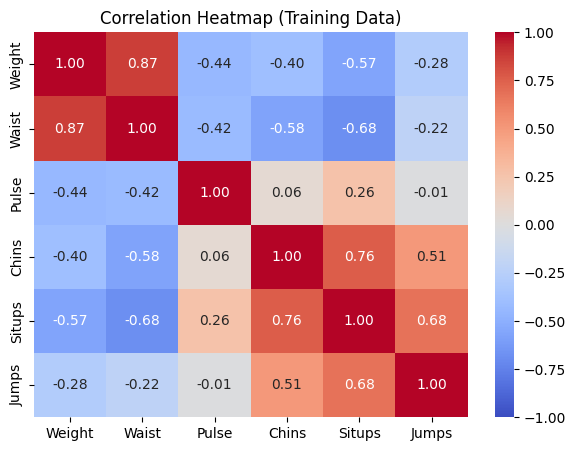

In [15]:
# Correlation heatmap: features and targets together
train_df = pd.concat([X_train, y_train], axis=1)
plt.figure(figsize=(7, 5))
sns.heatmap(train_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap (Training Data)")
plt.show()

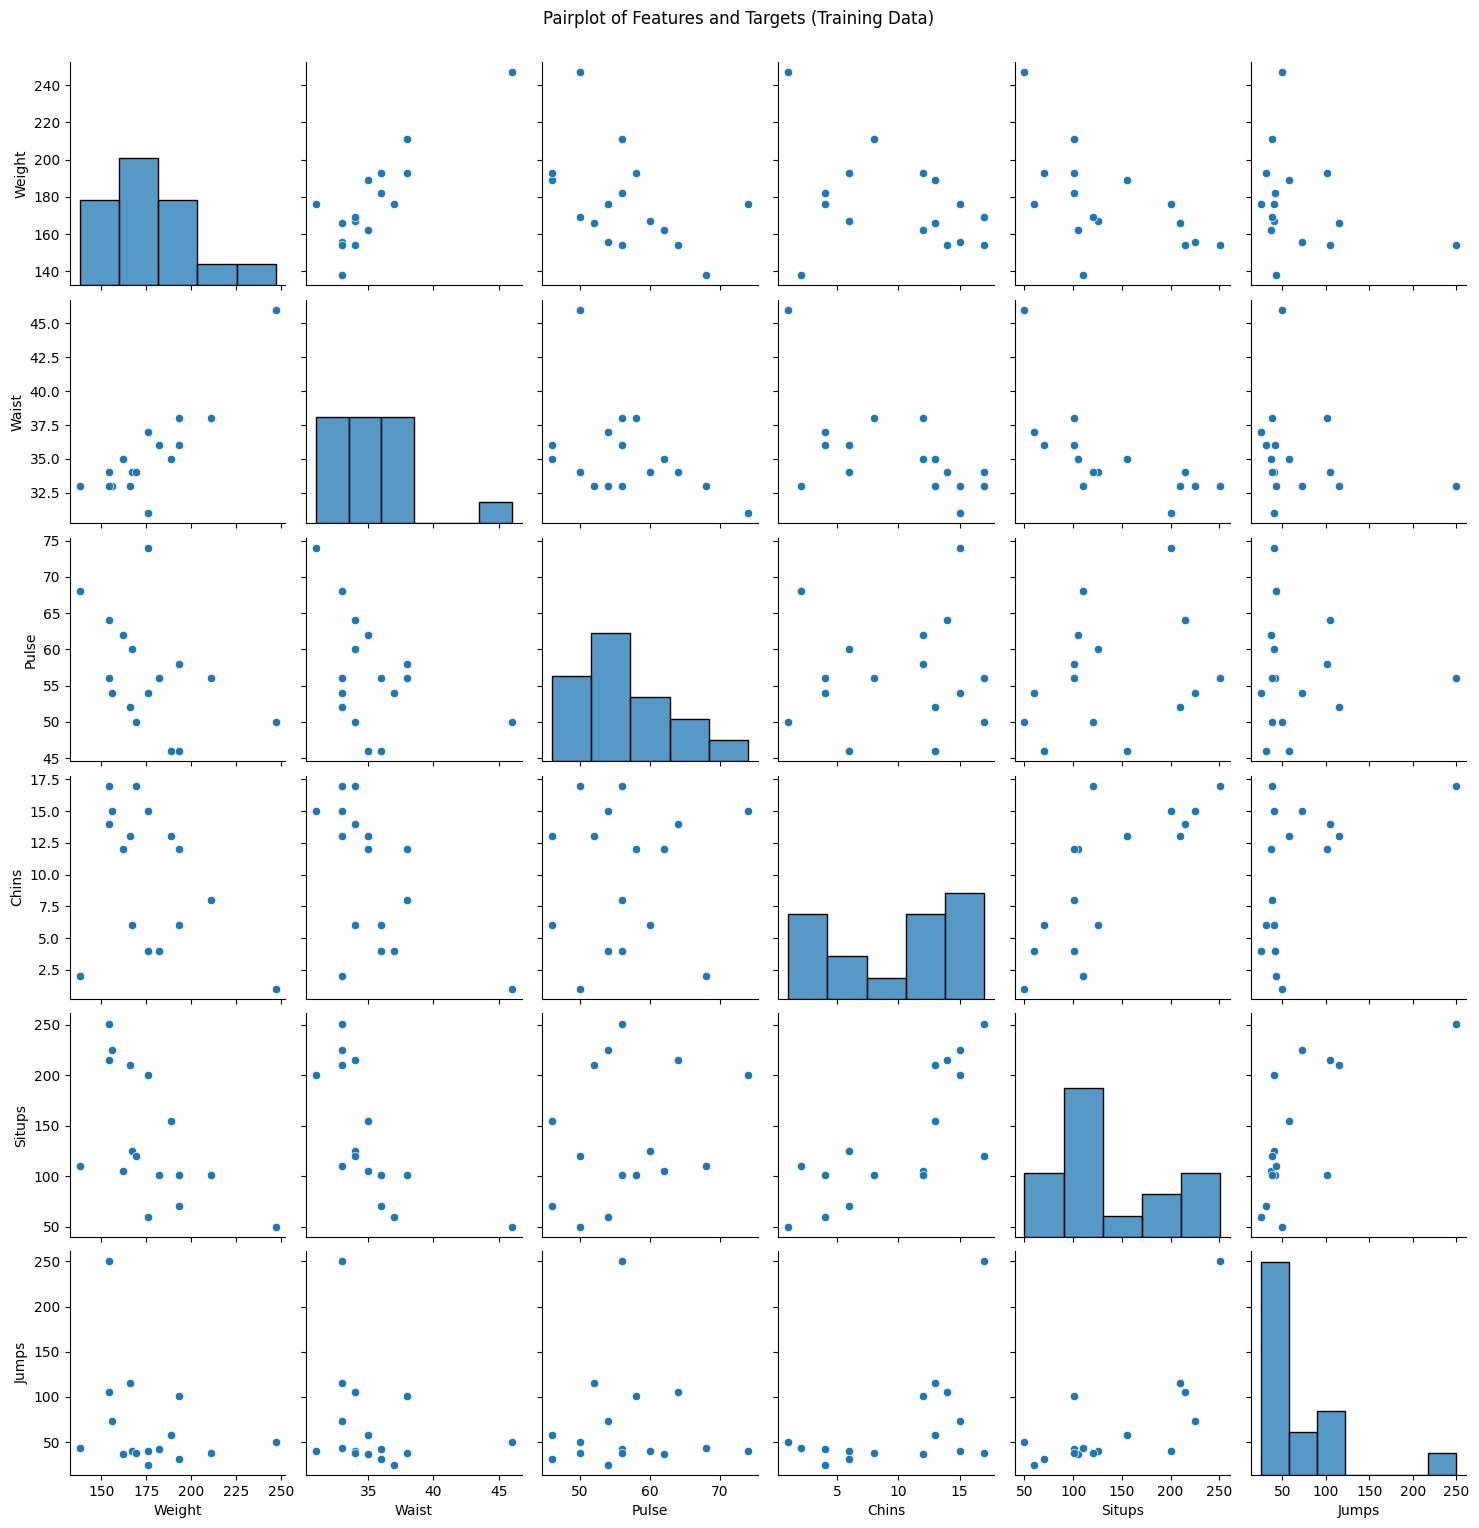

In [16]:
# Pairplot
sns.pairplot(train_df)
plt.suptitle("Pairplot of Features and Targets (Training Data)", y=1.02)
plt.show()

Correlation heatmap and pairplot:
- Waist has the strongest relationships with the targets, especially sit-ups (-0.68) and chin-ups (-0.58). People with larger waists tend to do fewer exercises.
- Weight also has negative relationships with the targets, the strongest being with sit-ups (-0.57).
- Pulse has almost no relationship with the targets (between -0.01 and 0.26).
- Weight and waist are strongly correlated with each other (0.87), so they carry similar information (multicollinearity).
- The three targets are related to each other. For example, chin-ups and sit-ups have a correlation of 0.76, so people who are good at one exercise tend to be good at the others.
- With only 16 people, the patterns in the pairplot are rough, and a single person can change a correlation a lot.

## Step 4: Build a Linear Regression Model

In [17]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)          # fits all 3 targets at once

y_pred = lin_reg.predict(X_test)
y_pred = pd.DataFrame(y_pred, columns=y.columns, index=y_test.index)

# Coefficients: one row per target, one column per feature
coef_table = pd.DataFrame(lin_reg.coef_, index=y.columns, columns=X.columns)
coef_table["Intercept"] = lin_reg.intercept_
display(coef_table.round(3))

,Weight,Waist,Pulse,Intercept
Chins,0.073,-1.520,-0.135,58.387
Situps,0.181,-13.925,-0.202,609.517
Jumps,-0.943,1.545,-1.243,250.634


### Interpretation

I trained one Linear Regression model on the three targets at the same time. It created a separate equation for each target, using the same three features. The coefficients show how much each target changes when a feature increases by 1, while the other features stay the same.

- Chins: each extra inch of waist is linked to about 1.5 fewer chin-ups. Weight and pulse have very small effects.
- Situps: each extra inch of waist is linked to about 14 fewer sit-ups. This is the largest effect in the model.
- Jumps: each extra pound of weight is linked to about 1 fewer jump, and each extra pulse beat to about 1.2 fewer jumps.

Some signs are unexpected. Weight has a small positive coefficient for chin-ups and sit-ups, even though it had a negative correlation with them, and waist has a positive coefficient for jumps. This is caused by multicollinearity: weight and waist are strongly correlated (0.87), so the model splits their effect between them in a way that makes individual coefficients hard to trust.

The intercepts (for example, 609.5 for sit-ups) are the predictions when all features are 0, which is not realistic, so they have no real meaning on their own.

## Step 5: Evaluate the Model

In [19]:
results = []
for target in y.columns:
    results.append({
        "Target": target,
        "R²": round(r2_score(y_test[target], y_pred[target]), 3),
        "RMSE": round(np.sqrt(mean_squared_error(y_test[target], y_pred[target])), 2),
        "Target mean (test)": round(y_test[target].mean(), 2)
    })
lr_results = pd.DataFrame(results)
print(lr_results.to_string(index=False))


Target     R²  RMSE  Target mean (test)
 Chins -0.530  5.14                 7.5
Situps -0.357 54.03               178.0
 Jumps -1.694 40.20                80.0


In [20]:
# Actual vs predicted for the 4 test people
display(pd.concat([y_test.add_suffix(" (actual)"), y_pred.round(1).add_suffix(" (pred)")], axis=1))

,Chins (actual),Situps (actual),Jumps (actual),Chins (pred),Situps (pred),Jumps (pred)
0,5.0,162.0,60.0,10.9,132.6,63.9
17,11.0,230.0,80.0,14.2,181.7,87.3
15,12.0,210.0,120.0,8.6,118.2,40.2
1,2.0,110.0,60.0,9.0,117.9,64.9


### Interpretation

I evaluated each target separately using R² and RMSE (Root Mean Squared Error):
- Chins: R² = -0.53, RMSE = 5.14 chin-ups (test average: 7.5)
- Situps: R² = -0.36, RMSE = 54.03 sit-ups (test average: 178)
- Jumps: R² = -1.69, RMSE = 40.20 jumps (test average: 80)

All three R² values are negative. This means the model predicted worse than simply guessing the average of the test set for every person. The errors are also large compared to the averages. For example, the chin-up error of about 5 is large when the average is 7.5.

Looking at the predictions for the 4 test people, the model tends to predict values close to the middle and misses the extremes. For example, person 15 did 210 sit-ups and 120 jumps, but the model predicted only 118 sit-ups and 40 jumps. Person 1 did only 2 chin-ups, but the model predicted 9.

Reasons for the poor performance:
- The test set has only 4 people, so one badly predicted person has a big effect on the scores.
- The model was trained on only 16 people, which is not enough to learn reliable patterns.
- The relationships between the features and targets are only moderate, and pulse has almost no relationship with the exercises.
- Weight and waist carry similar information (multicollinearity), and there are a few outliers.

## Step 6: Visualize Predictions

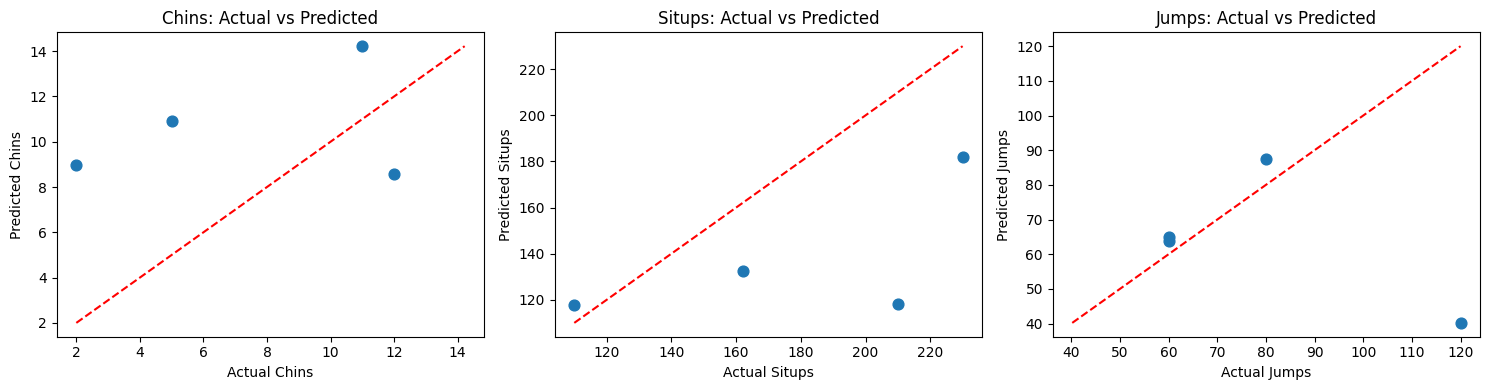

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, target in zip(axes, y.columns):
    ax.scatter(y_test[target], y_pred[target], s=60)
    low = min(y_test[target].min(), y_pred[target].min())
    high = max(y_test[target].max(), y_pred[target].max())
    ax.plot([low, high], [low, high], "r--")
    ax.set_xlabel(f"Actual {target}")
    ax.set_ylabel(f"Predicted {target}")
    ax.set_title(f"{target}: Actual vs Predicted")
plt.tight_layout()
plt.show()

### Interpretation

Each chart shows the 4 test people, with actual values on the x-axis and predicted values on the y-axis. The red dashed line shows perfect predictions.

- Chins: the points are scattered far from the line. The model predicted 9 chin-ups for a person who did only 2, and 8.6 for a person who did 12.
- Situps: one point is close to the line (about 110 actual vs 118 predicted), but the person who did 210 sit-ups was predicted at only about 118.
- Jumps: three points are close to the line (actual 60 and 80, predicted about 64 to 87), but the person who did 120 jumps was predicted at only about 40. This one person is the main reason jumps has the worst R².

Overall, the predictions stay in a narrow middle range, and the model fails to predict people with very high or very low results. With only 4 test points, one large miss has a big effect on the scores.

## Step 7: Make Predictions on New Data

In [22]:
# Take one test person, keeping the same columns as the training data
new_person = X_test.iloc[[0]]
print("Input data:")
display(new_person)

prediction = lin_reg.predict(new_person)
print("Predicted:", dict(zip(y.columns, prediction[0].round(1))))
print("Actual:   ", dict(zip(y.columns, y_test.iloc[0].values)))

Input data:


,Weight,Waist,Pulse
0,191.0,36.0,50.0


Predicted: {'Chins': np.float64(10.9), 'Situps': np.float64(132.6), 'Jumps': np.float64(63.9)}
Actual:    {'Chins': np.float64(5.0), 'Situps': np.float64(162.0), 'Jumps': np.float64(60.0)}


### Interpretation

I took the first person from the test set and predicted their exercise results. I kept the input as a one-row table with the same column names (Weight, Waist, Pulse), so it has the same structure as the training data.

- Chins: predicted 10.9, actual 5
- Situps: predicted 132.6, actual 162
- Jumps: predicted 63.9, actual 60

The jumps prediction is close (off by about 4), but the model overestimated chin-ups by about 6 and underestimated sit-ups by about 29. This shows the model can give a rough estimate for some targets but is not reliable for individual predictions.

## Step 8: Improving the Model and Comparing with Lasso Regression

In [23]:
from sklearn.model_selection import LeaveOneOut, cross_val_predict

loo = LeaveOneOut()

def loo_scores(model, X_data, name):
    pred = cross_val_predict(model, X_data, y, cv=loo)
    pred = pd.DataFrame(pred, columns=y.columns)
    row = {"Model": name}
    for t in y.columns:
        row[f"{t} R²"] = round(r2_score(y[t], pred[t]), 3)
        row[f"{t} RMSE"] = round(np.sqrt(mean_squared_error(y[t], pred[t])), 2)
    return row

In [24]:
# Feature engineering: waist-to-weight ratio, and a version without Pulse
X_fe = X.copy()
X_fe["Waist_per_Weight"] = X_fe["Waist"] / X_fe["Weight"] * 100
X_no_pulse = X[["Weight", "Waist"]]

comparison = [
    loo_scores(LinearRegression(), X, "Linear Regression (original)"),
    loo_scores(Pipeline([("scaler", StandardScaler()), ("lr", LinearRegression())]), X, "Linear Regression + scaling"),
    loo_scores(LinearRegression(), X_no_pulse, "Linear Regression (no Pulse)"),
    loo_scores(LinearRegression(), X_fe, "Linear Regression + Waist/Weight ratio"),
]
for a in [0.1, 1, 10]:
    comparison.append(loo_scores(Pipeline([("scaler", StandardScaler()), ("lasso", Lasso(alpha=a, max_iter=10000))]),
                                 X, f"Lasso (alpha={a})"))

print(pd.DataFrame(comparison).to_string(index=False))

                                 Model  Chins R²  Chins RMSE  Situps R²  Situps RMSE  Jumps R²  Jumps RMSE
          Linear Regression (original)    -0.011        5.18     -0.024        61.71    -0.432       59.82
           Linear Regression + scaling    -0.011        5.18     -0.024        61.71    -0.432       59.82
          Linear Regression (no Pulse)     0.093        4.91      0.132        56.81    -0.259       56.08
Linear Regression + Waist/Weight ratio    -0.959        7.21     -0.955        85.27    -1.231       74.65
                     Lasso (alpha=0.1)     0.045        5.03     -0.013        61.36    -0.407       59.28
                       Lasso (alpha=1)     0.156        4.73      0.084        58.37    -0.281       56.57
                      Lasso (alpha=10)    -0.108        5.42      0.269        52.14    -0.140       53.36


### Interpretation

Because the test set has only 4 people, I compared the models using Leave-One-Out cross-validation (LOO). Each of the 20 people was left out once, the model was trained on the other 19, and then it predicted the person who was left out. This gives a more reliable comparison, because every person is used for testing.

Results:
- Original Linear Regression: R² of -0.01 (chin-ups), -0.02 (sit-ups), and -0.43 (jumps). These are better than the 4-person test results, which shows the original test set was partly unlucky, but the model is still no better than guessing the average.
- Scaling (normalization) gave exactly the same results. This is expected, because Linear Regression's predictions do not change when the features are scaled.
- Removing Pulse improved all three targets (R² of 0.09, 0.13, and -0.26). Pulse had almost no relationship with the exercises, so removing it reduced noise.
- Adding a waist-to-weight ratio made the results much worse (R² around -1). It added another feature that overlaps with weight and waist, and with only 19 training people, the model overfit.
- Lasso with alpha = 1 gave the best result for chin-ups (R² 0.16, RMSE 4.73).
- Lasso with alpha = 10 gave the best results for sit-ups (R² 0.27, RMSE 52.14) and jumps (R² -0.14, RMSE 53.36), and the best average across all three targets.

### Which model performed best and why?
Lasso Regression performed best overall, but the best alpha depends on the target: alpha = 1 for chin-ups and alpha = 10 for sit-ups and jumps. Lasso helps because it shrinks the coefficients of weak or overlapping features, such as pulse and the overlap between weight and waist. This makes the model more stable when there are very few people to learn from. A very small alpha (0.1) behaves almost like plain Linear Regression, while a larger alpha reduces overfitting.

However, the improvements are small, and jumps are not predicted well by any model. With only 20 people, weight, waist, and pulse do not contain enough information to predict exercise performance accurately.

# Report

## Approach
I built a multi-output Linear Regression model on the Linnerud dataset, which predicts three targets (chin-ups, sit-ups, and jumps) at the same time from three body measurements (weight, waist, and pulse). The assignment described the inputs as age, weight, and height, but the dataset has weight, waist, and pulse instead, and scikit-learn stores the columns the other way around. I used the body measurements as inputs and the exercises as targets, without renaming or changing any data.

I split the data 80/20 (16 training, 4 test people), explored the training data, trained a Linear Regression model, evaluated each target with R² and RMSE, and predicted the results for one person. Because the test set was so small, I used Leave-One-Out cross-validation to compare improvements and Lasso Regression.

## Key findings
- Waist had the strongest relationship with the exercises, especially sit-ups (-0.68). Pulse had almost no relationship.
- Weight and waist were strongly correlated (0.87), which caused unexpected coefficient signs (multicollinearity).
- On the 4-person test set, all three R² values were negative, meaning the model did worse than guessing the average.
- With Leave-One-Out cross-validation, the results were more reliable but still weak. Scaling made no difference, removing pulse helped, and adding a waist-to-weight ratio made things worse.
- Lasso performed best overall (alpha = 1 for chin-ups, alpha = 10 for sit-ups and jumps), but the improvements were small, and jumps were not predicted well by any model.

## Multi-output regression
This was my first time predicting more than one target. Linear Regression fits a separate equation for each target using the same features, so I had to evaluate each target separately. A combined score would not make sense, because sit-ups (around 140) and chin-ups (around 10) are on very different scales. In real life, multi-output regression is useful when one set of inputs is used to predict several related results, such as predicting clicks, conversions, and revenue from ad spend.

## Reflections
- The biggest limitation is the dataset size. With only 20 people (and 4 in the test set), one person can change the scores a lot, so cross-validation was essential for a fair comparison.
- The model finds patterns, not cause and effect. It can show that men with larger waists tend to do fewer sit-ups, but not that reducing waist size will increase sit-ups.
- To improve the model, I would need more people, more varied participants (the data only includes middle-aged men), and more useful features, such as age, height, or training habits.